In [8]:
%load_ext autoreload
%autoreload 2

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from network_SIR import run_sir, run_many

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


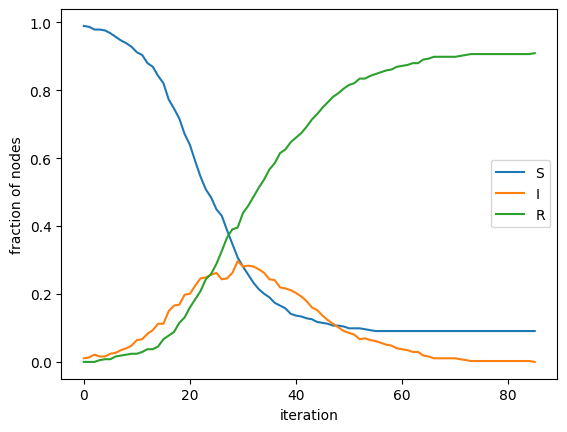

In [9]:
G = nx.erdos_renyi_graph(374, 0.02, seed=1)

rng = np.random.default_rng(1)
initial = rng.choice(374, size=4, replace=False)

S, I, R = run_sir(G, beta=0.05, gamma=0.1, initial_infected=initial, seed=1)

plt.plot(S, label="S")
plt.plot(I, label="I")
plt.plot(R, label="R")
plt.xlabel("iteration")
plt.ylabel("fraction of nodes")
plt.legend()
plt.show()

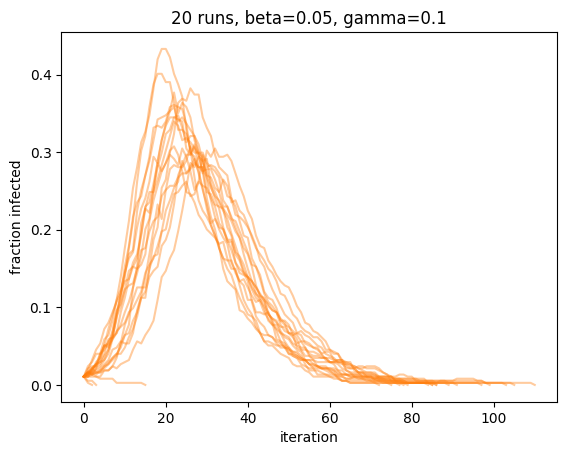

In [10]:
results = run_many(G, beta=0.05, gamma=0.1, n_init=4, n_runs=20)

for S, I, R in results:
    plt.plot(I, color="tab:orange", alpha=0.4)

plt.xlabel("iteration")
plt.ylabel("fraction infected")
plt.title("20 runs, beta=0.05, gamma=0.1")
plt.show()

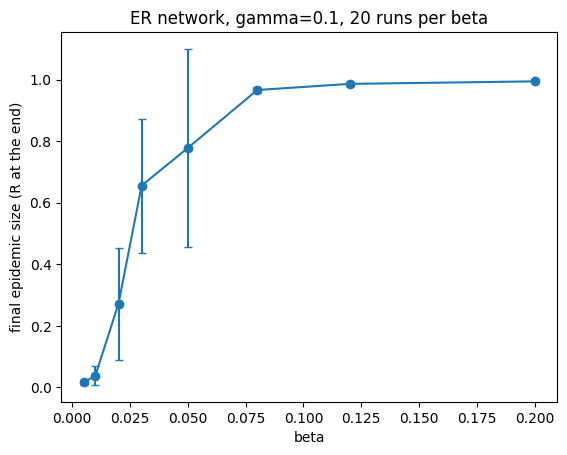

In [11]:
betas = [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2]
gamma = 0.1

mean_final = []
std_final = []

for beta in betas:
    results = run_many(G, beta, gamma, n_init=4, n_runs=20)
    final_sizes = [R[-1] for S, I, R in results]
    mean_final.append(np.mean(final_sizes))
    std_final.append(np.std(final_sizes))

plt.errorbar(betas, mean_final, yerr=std_final, marker="o", capsize=3)
plt.xlabel("beta")
plt.ylabel("final epidemic size (R at the end)")
plt.title("ER network, gamma=0.1, 20 runs per beta")
plt.show()

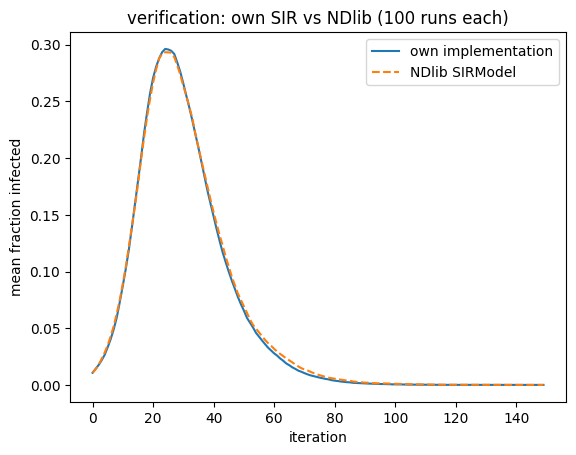

mean final size, own:   0.885
mean final size, NDlib: 0.905
KS test p-value: 0.908


In [13]:
from network_SIR import run_sir_ndlib

beta = 0.05
gamma = 0.1
n_runs = 100
T = 150

own_curves = []
ndlib_curves = []
own_final = []
ndlib_final = []

for r in range(n_runs):
    rng = np.random.default_rng(r)
    initial = rng.choice(374, size=4, replace=False)

    S, I, R = run_sir(G, beta, gamma, initial, n_iter=T, seed=r)
    own_curves.append(np.pad(I, (0, T - len(I)), mode="edge")[:T])
    own_final.append(R[-1])

    S, I, R = run_sir_ndlib(G, beta, gamma, initial, n_iter=T, seed=r)
    ndlib_curves.append(I[:T])
    ndlib_final.append(R[-1])

plt.plot(np.mean(own_curves, axis=0), label="own implementation")
plt.plot(np.mean(ndlib_curves, axis=0), "--", label="NDlib SIRModel")
plt.xlabel("iteration")
plt.ylabel("mean fraction infected")
plt.title(f"verification: own SIR vs NDlib ({n_runs} runs each)")
plt.legend()
plt.savefig("figures/verification_ndlib.png", dpi=200, bbox_inches="tight")
plt.show()

print("mean final size, own:  ", round(np.mean(own_final), 3))
print("mean final size, NDlib:", round(np.mean(ndlib_final), 3))
from scipy.stats import ks_2samp
print("KS test p-value:", round(ks_2samp(own_final, ndlib_final).pvalue, 3))